In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from tqdm import tqdm
from cmcrameri import cm
from archetypes_re2020.data.remove_extreme_outliers import outliers

In [28]:
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

cmap = cm.berlin

In [2]:
import bw2data as bd
import bw2io as bi
bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")
bd.databases

22:46:38+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


Databases dictionary with 12 object(s):
	2026-4-23-18h10_archetypes_RE2020_PRB
	2026-5-7-20h29_archetypes_RE2020_MIB
	2026-5-7-20h29_bernoulli_RE2020
	2026-8-10-0h50_buildings_cons_RE2020
	2026-8-13-16h52_archetypes_RE2020_BB
	2026-8-9-22h39_processes_RE2020
	2026-8-9-23h6_buildings_RE2020
	2026-8-9_composants_yc_consos
	2026-8-9_consumptions_processes
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	open_spaces

In [30]:
import bw2data as bd

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")
arch_db = bd.Database("2026-8-13-16h52_archetypes_RE2020_BB")
dict_w = {}

for a in tqdm(arch_db) :
    phi = list(a.production())[0]["amount"]
    tmp = {e["input"][1] : e["amount"]/phi for e in tqdm(a.technosphere(),leave = False)}
    dict_w = dict_w | tmp

  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:01<00:00,  3.25it/s]


In [31]:
programmes = {
    1991 : {
    "individual_housing" : 0,
    "collective_housing" : 520000,
    "office_building" : 900000,
    # "industrial_building" : 165000,
    "education_building" : 582000,
    "roads" : 100000,
    "vegetation" : 53000,
    },
    1997 : {
    "individual_housing" : 0,
    "collective_housing" : 520000,
    "office_building" : 900000,
    # "industrial_building" : 150000,
    "education_building" : 684000,
    "roads" : 100000,
    "vegetation" : 80600,
    },
    2002 : {
    "individual_housing" : 0,
    "collective_housing" : 430000,
    "office_building" : 700000,
    # "industrial_building" : 150000,
    "education_building" : 920000,
    "roads" : 100000,
    "vegetation" : 100000,
    },
    2009 : {
    "individual_housing" : 0,
    "collective_housing" : 585000,
    "office_building" : 745000,
    # "industrial_building" : 150000,
    "education_building" : 920000,
    "roads" : 100000,
    "vegetation" : 100000,
    }
    }

In [32]:
to_assess = {k : programmes[1991][k] - programmes[2009][k] for k in programmes[1991].keys()}
to_assess

{'individual_housing': 0,
 'collective_housing': -65000,
 'office_building': 155000,
 'education_building': -338000,
 'roads': 0,
 'vegetation': -47000}

In [33]:
import polars as pl
Hb_gwp= pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Hb/260810-Hb/scores_climate change_global warming potential (GWP100)_1000.parquet")
Hb_aware = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Hb/260810-Hb/scores_water use_user deprivation potential (deprivation-weighted water consumption)_1000.parquet")

In [34]:
Hb_gwp = Hb_gwp.with_columns(
    poids = pl.col("batiment").replace_strict(dict_w, default = 0.,return_dtype = pl.Float64)
)
Hb_aware = Hb_aware.with_columns(
    poids = pl.col("batiment").replace_strict(dict_w, default = 0.,return_dtype = pl.Float64)
)

In [35]:
map_arch = {
    "individual_housing" : "Maison individuelle ou accolée",
    "collective_housing" : "Logement collectif",
    "office_building" : "Bureau",
    # "industrial_building" : "Bureau",
    # "education_building" : 'Enseignement secondaire (partie jour)',
    "education_building" : "Bureau",
    "roads" : "roads",
    "vegetation" : "vegetation"}

In [36]:
Hp_gwp = Hb_gwp.drop_nulls("usage")
Hp_aware = Hb_aware.drop_nulls("usage")

list_Hps = [Hp_gwp,Hp_aware]

In [ ]:
updated_Hps = []

for Hp in list_Hps:
    # valeurs aberrantes par usage
    parts = Hp.partition_by('usage')
    Hp = pl.concat([outliers(part, "score") for part in parts])

    # On projette le projet urbain sur f tilde
    f_tilde = {k: 0 for k in Hp["usage"].unique()}

    for k, v in to_assess.items():
        key = map_arch[k]
        if key not in f_tilde:
            print(f"{k} non considéré")
            continue
        else:
            f_tilde[key] += v

    # On enlève les poids nuls, on pondère les non nuls
    Hp = Hp.filter(pl.col("usage").is_in([k for k, v in f_tilde.items() if v != 0]))

    expr = pl.col("score")
    for k, v in f_tilde.items():
        if v != 0:
            expr = pl.when(pl.col("usage") == k).then(pl.col("score") * v).otherwise(expr)

    Hp = Hp.with_columns(expr.alias("score"))

    updated_Hps.append(Hp)

roads non considéré
vegetation non considéré
roads non considéré
vegetation non considéré


In [12]:
updated_Hps

[shape: (2_012_000, 8)
 ┌───────────┬──────────┬────────────┬────────────┬────────────┬──────────┬────────────┬────────────┐
 │ iteration ┆ batiment ┆ usage      ┆ score      ┆ indicator  ┆ poids    ┆ score_mild ┆ score_extr │
 │ ---       ┆ ---      ┆ ---        ┆ ---        ┆ ---        ┆ ---      ┆ _outliers  ┆ eme_outlie │
 │ i64       ┆ cat      ┆ cat        ┆ f32        ┆ str        ┆ f64      ┆ ---        ┆ rs         │
 │           ┆          ┆            ┆            ┆            ┆          ┆ bool       ┆ ---        │
 │           ┆          ┆            ┆            ┆            ┆          ┆            ┆ bool       │
 ╞═══════════╪══════════╪════════════╪════════════╪════════════╪══════════╪════════════╪════════════╡
 │ 0         ┆ 615117_1 ┆ Bureau     ┆ -2.4710e8  ┆ ecoinvent- ┆ 0.003623 ┆ false      ┆ false      │
 │           ┆          ┆            ┆            ┆ 3.11 | EF  ┆          ┆            ┆            │
 │           ┆          ┆            ┆            ┆ v3.1 | 

In [13]:
to_graph = updated_Hps[0].filter(pl.col("score_extreme_outliers")==False)
# to_graph = updated_Hps[0]

In [14]:
Hb_gwp

iteration,batiment,usage,score,indicator,poids
i64,cat,cat,f32,str,f64
0,"""392011_1""","""Maison individuelle ou accolée""",1306.674072,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000008
1,"""392011_1""","""Maison individuelle ou accolée""",1292.127441,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000008
2,"""392011_1""","""Maison individuelle ou accolée""",1372.894287,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000008
3,"""392011_1""","""Maison individuelle ou accolée""",1301.349121,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000008
4,"""392011_1""","""Maison individuelle ou accolée""",1352.156494,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000008
…,…,…,…,…,…
995,"""583487_1""","""Maison individuelle ou accolée""",1161.979858,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000014
996,"""583487_1""","""Maison individuelle ou accolée""",1126.776978,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000014
997,"""583487_1""","""Maison individuelle ou accolée""",1081.633789,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000014


In [15]:
updated_Hps[0]

iteration,batiment,usage,score,indicator,poids,score_mild_outliers,score_extreme_outliers
i64,cat,cat,f32,str,f64,bool,bool
0,"""615117_1""","""Bureau""",-2.4710e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
1,"""615117_1""","""Bureau""",-2.2068e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
2,"""615117_1""","""Bureau""",-2.1094e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
3,"""615117_1""","""Bureau""",-2.1560e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
4,"""615117_1""","""Bureau""",-2.3274e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
…,…,…,…,…,…,…,…
995,"""569167_1""","""Logement collectif""",-1.1552e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000482,false,false
996,"""569167_1""","""Logement collectif""",-1.0216e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000482,false,false
997,"""569167_1""","""Logement collectif""",-1.0237e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000482,false,false


In [16]:
to_graph

iteration,batiment,usage,score,indicator,poids,score_mild_outliers,score_extreme_outliers
i64,cat,cat,f32,str,f64,bool,bool
0,"""615117_1""","""Bureau""",-2.4710e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
1,"""615117_1""","""Bureau""",-2.2068e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
2,"""615117_1""","""Bureau""",-2.1094e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
3,"""615117_1""","""Bureau""",-2.1560e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
4,"""615117_1""","""Bureau""",-2.3274e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.003623,false,false
…,…,…,…,…,…,…,…
995,"""569167_1""","""Logement collectif""",-1.1552e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000482,false,false
996,"""569167_1""","""Logement collectif""",-1.0216e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000482,false,false
997,"""569167_1""","""Logement collectif""",-1.0237e8,"""ecoinvent-3.11 | EF v3.1 | cli…",0.000482,false,false


In [17]:
to_assess

{'individual_housing': 0,
 'collective_housing': -65000,
 'office_building': 155000,
 'industrial_building': 15000,
 'education_building': -338000,
 'roads': 0,
 'vegetation': -47000}

In [18]:
pl.Config.set_streaming_chunk_size(10_000)

result = (
    updated_Hps[0].lazy()
    .group_by("iteration", "indicator")
    .agg(pl.col("score").sum())
    .collect(engine="streaming")
)

<Axes: xlabel='score'>

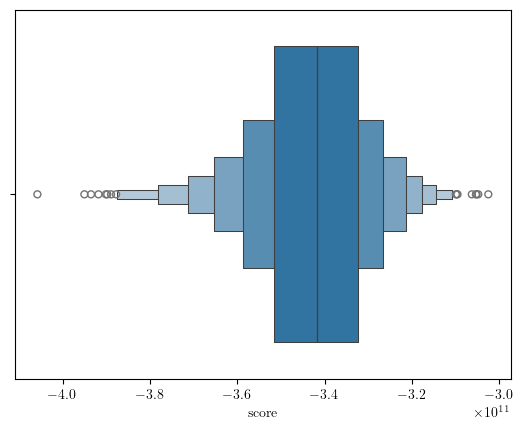

In [19]:
sns.boxenplot(data = outliers(result,"score").filter(pl.col("score_extreme_outliers") == False),x = "score")


In [21]:
result

iteration,indicator,score
i64,str,f32
766,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.3921e11
9,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.5374e11
10,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.4366e11
11,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.4257e11
31,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.3932e11
…,…,…
944,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.6782e11
948,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.4799e11
963,"""ecoinvent-3.11 | EF v3.1 | cli…",-3.5361e11


In [ ]:
result_dict[]

In [22]:
result_dict = {}

In [5]:
Fb = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/Erreurs/final_demand_vector_error.parquet")

In [6]:
Fb

code_bat,code_composant,q,theta,usage,S,error
str,str,f64,f64,str,f64,f64
"""482764_1""","""charpentes_bois_m³_100""",0.039987,0.050528,"""Maison individuelle ou accolée""",78.0,-0.822204
"""516613_1""","""revêtements extérieurs des faç…",1.288547,1.386239,"""Maison individuelle ou accolée""",116.3,-11.361579
"""454241_1""","""transfert d’énergie et de donn…",0.053333,0.111823,"""Maison individuelle ou accolée""",91.5,-5.351814
"""433057_1""","""cloisonnement / plafonds-suspe…",3.35098,3.337163,"""Maison individuelle ou accolée""",137.7,1.902706
"""360051_1""","""eléments de couverture en peti…",0.857143,0.826452,"""Maison individuelle ou accolée""",90.3,2.771387
…,…,…,…,…,…,…
"""571720_1""","""receveur de douche_matériau de…",0.019084,0.001641,"""Maison individuelle ou accolée""",104.8,1.82802
"""532545_1""","""revêtements pour murs et plafo…",0.077835,0.017762,"""Maison individuelle ou accolée""",115.5,6.93848
"""621523_1""","""portes (intérieur / extérieur …",0.110531,0.080742,"""Maison individuelle ou accolée""",103.5,3.083185


In [7]:
usage = "Maison individuelle ou accolée"

Fb = Fb.filter(pl.col("usage")==usage,~pl.col("code_composant").str.contains_any(
        ["consommation", "Consommation"]
    ))

composants = Fb["code_composant"].unique()
batiments = Fb["code_bat"].unique()

In [8]:
Fb

code_bat,code_composant,q,theta,usage,S,error
str,str,f64,f64,str,f64,f64
"""482764_1""","""charpentes_bois_m³_100""",0.039987,0.050528,"""Maison individuelle ou accolée""",78.0,-0.822204
"""516613_1""","""revêtements extérieurs des faç…",1.288547,1.386239,"""Maison individuelle ou accolée""",116.3,-11.361579
"""454241_1""","""transfert d’énergie et de donn…",0.053333,0.111823,"""Maison individuelle ou accolée""",91.5,-5.351814
"""433057_1""","""cloisonnement / plafonds-suspe…",3.35098,3.337163,"""Maison individuelle ou accolée""",137.7,1.902706
"""360051_1""","""eléments de couverture en peti…",0.857143,0.826452,"""Maison individuelle ou accolée""",90.3,2.771387
…,…,…,…,…,…,…
"""571720_1""","""receveur de douche_matériau de…",0.019084,0.001641,"""Maison individuelle ou accolée""",104.8,1.82802
"""532545_1""","""revêtements pour murs et plafo…",0.077835,0.017762,"""Maison individuelle ou accolée""",115.5,6.93848
"""621523_1""","""portes (intérieur / extérieur …",0.110531,0.080742,"""Maison individuelle ou accolée""",103.5,3.083185


In [9]:
Fb_q = Fb.pivot("code_composant", index="code_bat", values="q").fill_null(0.)

In [10]:
Fb_q

code_bat,charpentes_bois_m³_100,revêtements extérieurs des façades compris les systèmes composites d’isolation thermique extérieure_mortier ou colle minéral_m²_50,transfert d’énergie et de données à l’intérieur du bâtiment_câbles de communication cuivre et fibres optiques_m_10,cloisonnement / plafonds-suspendus_rails métalliques_m_50,eléments de couverture en petits éléments_terre cuite_m²_100,gaines / fourreaux_polyéthylène_m_50,"prises_prises diverses (tv, hp, informatique…)_unité_20",eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_béton armé_m³_100,isolation_eléments de fixation et accessoires de pose_unité_50,plinthes / moulures_céramique_m_30,cloisonnement_plaque de plâtre_m²_50,réseaux d’énergie_câbles basse tension < 1kv_m_30,eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_appui de baie_m_50,wc - toilette - cuvette_céramique (porcelaine vitrifiée)_unité_20,dalles et prédalles_béton plein armé_m²_100,réseaux d'adduction d'eau (intérieur et extérieur)_laiton_unité_25,menuiseries intérieures et extérieures / fermetures_divers_m²_10,petits éléments de maçonnerie_béton_m²_100,murs (éléments architecturaux)_bois_m²_100,receveur de douche_céramique (grès émaillé et porcelaine vitrifiée)_unité_20,diffusion d’air_bouches d’extraction_unité_17,revêtements de sol durs_céramique_m²_50,conduits et accessoires de réseaux_coudes et accessoires_unité_25,lavabo_céramique (grès émaillé et porcelaine vitrifiée)_unité_20,"produits de traitement des surfaces_etanchéité, imperméabilisation, hydrofugation_m²_50","produits de collage, fixation et scellement_mortiers-colles en poudre_m²_50",chauffage à énergie électrique directe à poste fixe visible_rayonnant_unité_17,"equipements sanitaires, de salles d'eau et de cuisine_robinetterie et colonnes de douche_unité_12",réseaux d'adduction d'eau (intérieur et extérieur)_cuivre_m_100,"equipements sanitaires, de salles d'eau et de cuisine_divers_unité_15",equipements de génie climatique_divers_unité_15,isolants acoustiques pour cloisons_laine de verre_m²_50,"produits d'étanchéité et d'imperméabilisation pour murs enterrés_membranes synthétiques (pvc, polyoléfines,...)_m²_50",fenêtres / portes fenêtres_pvc_m²_30,conduits et accessoires de réseaux_conduits flexibles_m_15,plinthes / moulures_bois_m_30,…,caisson de ventilation_vmc simple flux_m3/h_17,revêtements des sols et murs / peintures / produits de décoration _divers_m_20,isolants thermiques et acoustiques sous dalles_laine de roche_m²_50,réseaux d'adduction d'eau (intérieur et extérieur)_acier galvanisé_m_30,voirie / réseaux divers (y compris réseaux intérieurs) et aménagements extérieurs de la parcelle_chambres d'accès ou de tirage_unité_100,conversion_onduleurs synchrones_unité_15,conduits et accessoires de réseaux_conduits rigides_m_17,isolants thermiques et acoustiques pour murs (ite)_laine de roche_m²_50,traitement d’air_centrale double flux_unité_17,"peintures, lasures et vernis, enduits de peintures (hors saturateurs)_lasures et vernis solvant_m²_8",voirie / réseaux divers (y compris réseaux intérieurs) et aménagements extérieurs de la parcelle_divers_m²_20,isolation thermique et acoustique des tuyaux/conduits/équipements_traitement acoustique_unité_30,pompes à chaleur individuelles_air/eau_unité_22,eléments porteurs verticaux (poteaux / colonnes / piliers) _acier_kg_100,revêtements de sol souples_pvc_m²_10,conduits et accessoires de réseaux_conduits rigides_unité_30,réseaux d'adduction du gaz_polyéthylène_m_50,désenfumage_ caisson de désenfumage seul_unité_17,plafonds suspendus / plafonds tendus_laine de verre_m²_50,réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_fonte_unité_30,cloisonnement / plafonds-suspendus_cloison mobile / amovible_m²_50,voirie / réseaux divers (y compris réseaux intérieurs) et aménagements extérieurs de la parcelle_divers_unité_10,voirie / réseaux divers (y compris réseaux intérieurs) et aménagements extérieurs de la 

In [11]:
row_labels = Fb_q["code_bat"].to_list()
col_labels = Fb_q.columns[1:]
weights = np.array([dict_w[k] for k in Fb_q["code_bat"].to_list()])

Fb_q_array = Fb_q.drop("code_bat").to_numpy()

In [12]:
Mcov = np.cov(Fb_q_array,aweights=weights,rowvar=False)

In [13]:
mask = np.eye(Mcov.shape[0], dtype=bool)

<Axes: >

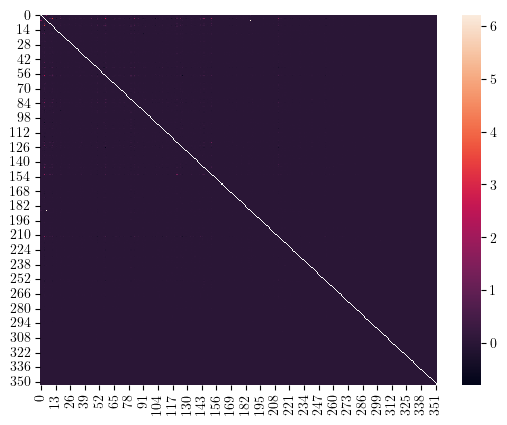

In [14]:
# sns.heatmap(Mcov[70:90,70:90])
sns.heatmap(Mcov,mask = mask)

In [100]:
col_labels[79]

'complexes de doublage_plaque de plâtre + polystyrène expansé_m²_50'

In [15]:
std_devs = np.sqrt(np.diag(Mcov))
std_devs[std_devs == 0] = 1e-10

Mcorr = Mcov / np.outer(std_devs, std_devs)

In [43]:
from matplotlib.colors import ListedColormap
full_cmap = cm.vik

partial_colors = full_cmap(np.linspace(0.1, 0.9, 100))

# Create new ListedColormap from the slice
cmap_partial = ListedColormap(partial_colors, name='oslo_partial')


<Axes: >

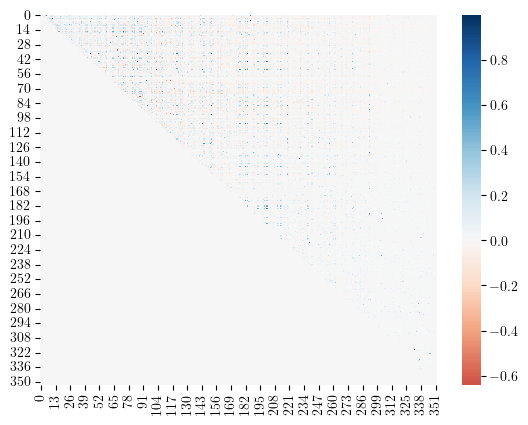

In [44]:
sns.heatmap(np.triu(Mcorr,k = 1),cmap = "RdBu",center=0)

In [45]:
eigenvalues, eigenvectors = np.linalg.eig(Mcorr)

pc1_loadings = eigenvectors[:, np.argmax(eigenvalues)]
sorted_indices = np.argsort(pc1_loadings)[::-1]

sorted_corr = Mcorr[np.ix_(sorted_indices, sorted_indices)]

In [46]:
sorted_indices

array([ 73,  81,  58,  88,  41, 108,  50,  64,  15,  12,  89,  27, 126,
        40, 147,  74,  71,   9,  98, 158,  48,  91,  65,  34,   4, 220,
       142,  46,  33, 157,  75,  22,  92,  94,  83,  79, 113, 137,  62,
       102,  35,   1, 231,  21, 166,  26,  80, 169,  63, 143,  93, 248,
       188,  70, 139, 311, 164, 321, 180, 253,  38, 266, 154,  20, 208,
       162, 322, 156, 275,   0, 342,  61, 308, 172, 240, 352, 293, 224,
       348, 133,  99, 333,  60,  25, 334, 351,  84, 269, 305, 340, 167,
       304, 129, 324, 345, 326, 347, 268, 194, 104, 252,  42, 296,  53,
       328, 212, 258, 274, 131, 331, 336, 301, 318, 307, 281, 316,  24,
       338, 265, 111, 209, 264, 218, 350, 216, 313, 183, 173, 263, 309,
       181, 299, 317, 349, 300,  28, 200, 346, 186, 329,  13, 127, 310,
       196, 116, 291, 343, 244, 195,  47, 344, 259, 123, 298, 302, 159,
       290, 325, 256, 254, 315, 239, 228, 314, 312, 270, 243, 249, 278,
       335, 227, 295, 286, 332,  49, 303,  85, 319, 276, 341, 33

In [54]:
xmin = 0
xmax = 15
ymin = 0
ymax = 15

In [55]:
sorted_column_names = [col_labels[i] for i in sorted_indices]

[Text(0, 0, "produits d'étanchéité et d'imperméabilisation pour murs enterrés_feuilles à base de bitume_m²_60"),
 Text(0, 1, "réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_béton_unité_50"),
 Text(0, 2, "réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_pvc_m_100"),
 Text(0, 3, 'volets / volets roulants / persiennes / stores / brise-soleil_pvc_m²_30'),
 Text(0, 4, 'portes (intérieur / extérieur / portail…)_acier_m²_25'),
 Text(0, 5, 'structure / maçonnerie / gros œuvre / charpente_divers_m²_50'),
 Text(0, 6, 'isolants thermiques et acoustiques en vrac_laine de verre_m²_50'),
 Text(0, 7, 'eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_terre cuite_m_100'),
 Text(0, 8, "réseaux d'adduction d'eau (intérieur et extérieur)_laiton_unité_25"),
 Text(0, 9, 'eléments porteurs horizontaux (poutres / poutrelles / entrevous / hourdis / linteaux)_appui de baie_m_50'),
 Text(0, 10, 'baignoire_matériau de synthèse_un

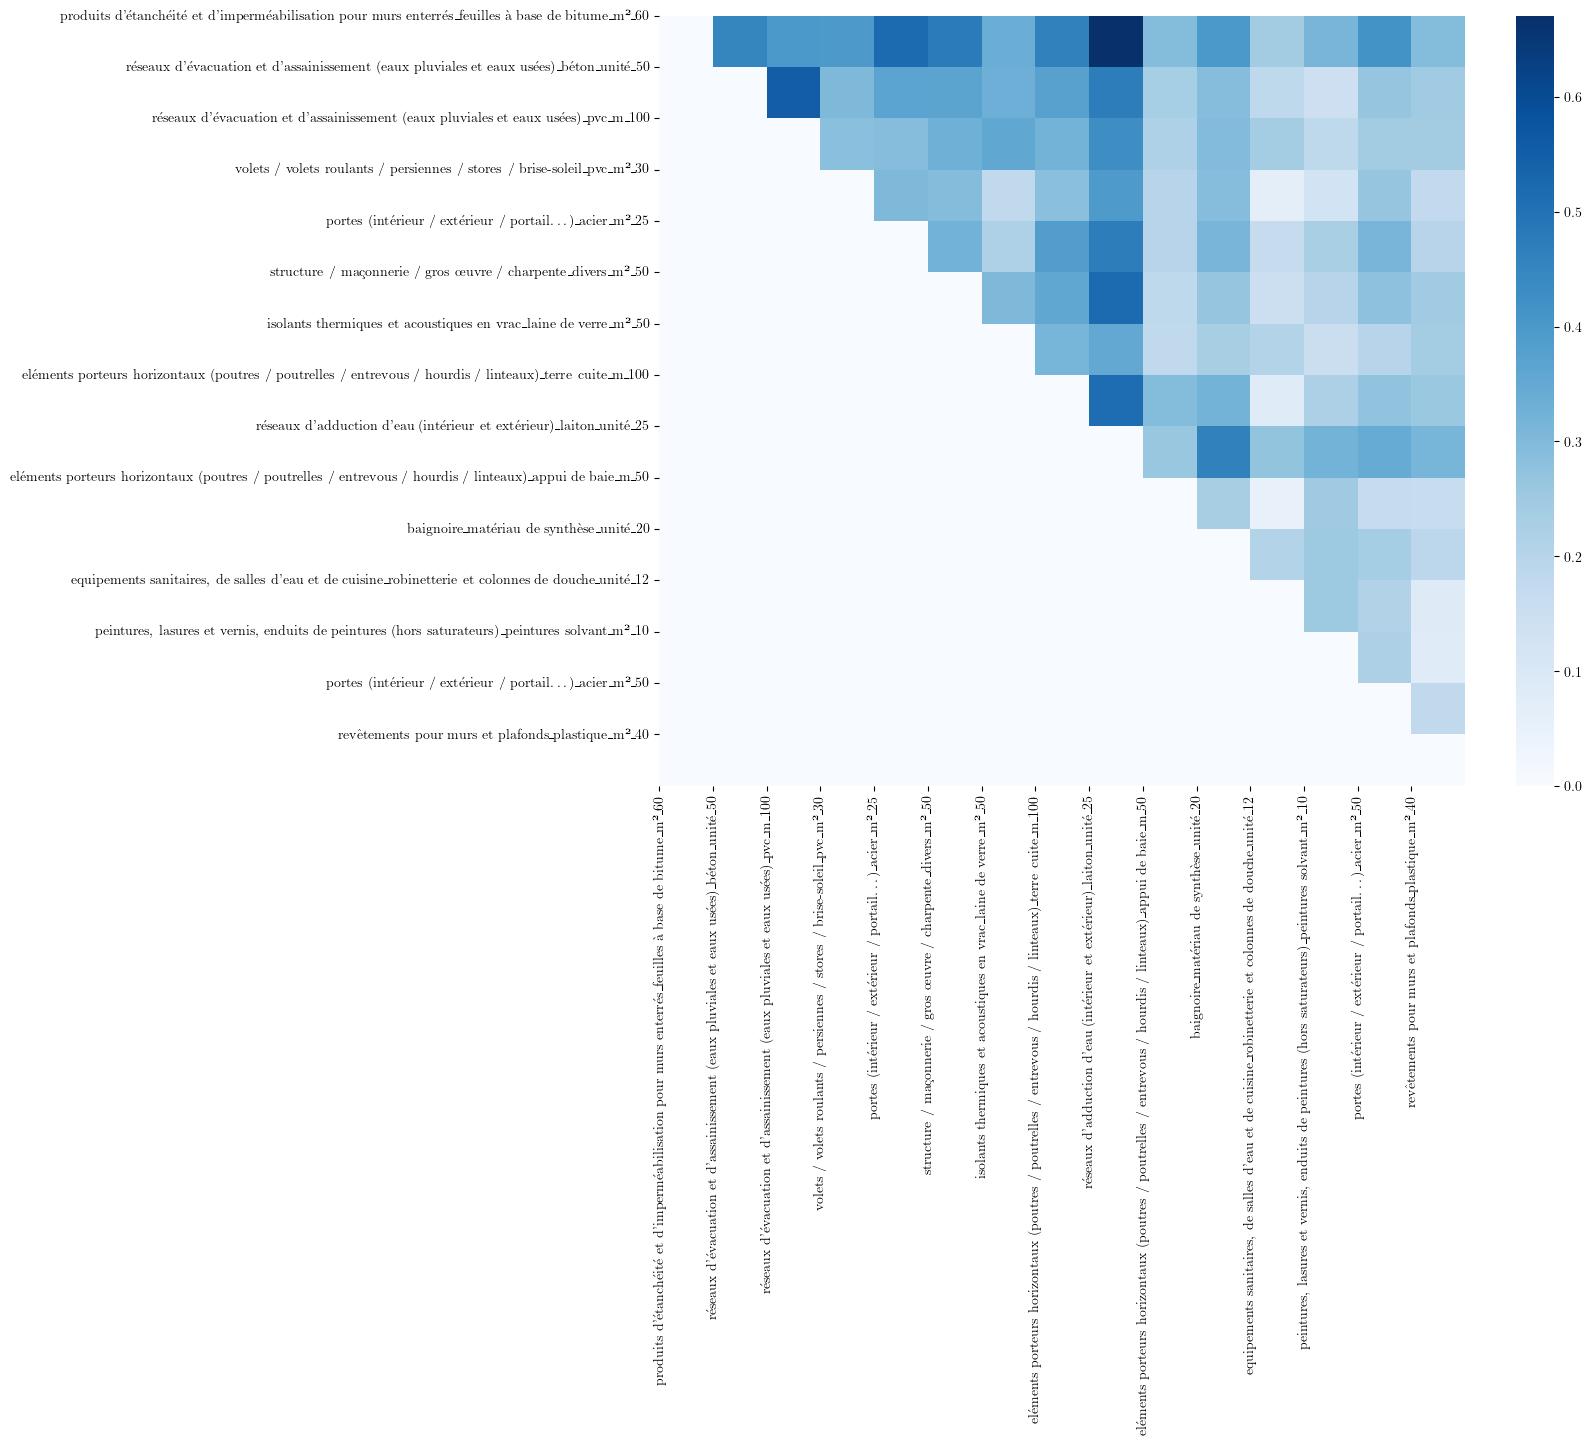

In [56]:
fig, ax = plt.subplots(figsize = (13,10))
sns.heatmap(np.triu(sorted_corr[xmin:xmax,ymin:ymax],k=1), cmap = "Blues")
n = len
ax.set_xticks(range(xmin,xmax))
ax.set_yticks(range(ymin,ymax))

ax.tick_params(axis='x',which = 'both',rotation=90)
ax.tick_params(axis='y',which = 'both',rotation=0)
ax.set_xticklabels(sorted_column_names[xmin:xmax])
ax.set_yticklabels(sorted_column_names[ymin:ymax])



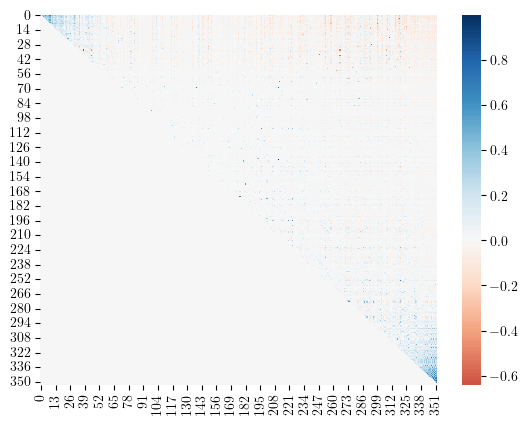

In [53]:
fig, ax = plt.subplots()
sns.heatmap(np.triu(sorted_corr,k = 1),cmap = "RdBu",center=0)
plt.savefig("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/matrice_correlation.pdf",dpi=300)

In [171]:

flat_indices = np.argpartition(Mcorr.ravel(), -10)[-10:] 
flat_indices = flat_indices[np.argsort(Mcorr.ravel()[flat_indices])[::-1]]
row_indices, col_indices = np.unravel_index(flat_indices, Mcorr.shape)

indices = list(zip(row_indices, col_indices))



In [178]:
upper_triu = np.abs(np.triu(sorted_corr[xmin:xmax,ymin:ymax],k=1))
flat_indices = np.argpartition(upper_triu.ravel(), -380)[-380:]
flat_indices = flat_indices[np.argsort(upper_triu.ravel()[flat_indices])[::-1]]
indices = list(zip(*np.unravel_index(flat_indices, upper_triu.shape)))

In [179]:
d = {(sorted_column_names[i],sorted_column_names[j]) : sorted_corr[i,j] for (i,j) in indices }

In [182]:
[k for k,v in d.items() if v<0]

[('fenêtres / portes fenêtres_pvc_m²_30',
  'fenêtres / portes fenêtres_aluminium_m²_30'),
 ('volets / volets roulants / persiennes / stores / brise-soleil_pvc_m²_30',
  'volets / volets roulants / persiennes / stores / brise-soleil_aluminium_m²_30'),
 ('petits éléments de maçonnerie_terre cuite_m²_100',
  'petits éléments de maçonnerie_béton_m²_100'),
 ('chauffe-eau individuel à accumulation_chauffe-eau thermodynamique_unité_17',
  'pompes à chaleur individuelles_air/eau_unité_17'),
 ('pompes à chaleur individuelles_air/air_unité_17',
  'pompes à chaleur individuelles_air/eau_unité_17'),
 ('isolants thermiques et acoustiques sous chape_polyuréthane_m²_50',
  'isolants thermiques et acoustiques pour murs (iti)_polyuréthane_m²_50'),
 ("equipements sanitaires, de salles d'eau et de cuisine_robinetterie et colonnes de douche_unité_12",
  "equipements sanitaires, de salles d'eau et de cuisine_robinetterie et colonnes de douche_unité_16"),
 ('système pour cloisons_laine de verre_m²_50',
  '

In [113]:

sorted_column_names = [col_labels[i] for i in sorted_indices]

In [88]:
col_labels[33]

'diffusion d’air_terminaux passifs_unité_17'

In [87]:
col_labels[323]

'coffrets_coffrets saillie_unité_20'